# Nakasato wind generation forecasting
### A standalone weather ensemble — no SCADA required

This notebook uses the 13 coordinates from your map and your uploaded V117 power curve.
The included example has **31 GFS + 51 ECMWF weather members**, weighted 50:50 by family.
JMA MSM is a separate benchmark. Default output is the next **24 hourly timestamps**, with **no SCADA required**.

**Status:** runnable physical weather ensemble. API forecasts and the supplied power curve are sufficient.
Measured plant accuracy has not yet been established; an ensemble-versus-LSTM advantage is not assumed.

Extract the **entire project ZIP** before running. Install `requirements.txt` in your Python environment.
The default cells reproduce the saved snapshot **without internet access**. Live fetching and ML
training require you to enable their respective optional cells.


In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

candidates = [Path.cwd(), Path.cwd()/"Nakasato_Wind_Forecast", Path.cwd()/"wind_forecast"]
ROOT = next((p for p in candidates if (p/"config.json").exists() and (p/"data/turbines.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Set ROOT to the extracted Nakasato_Wind_Forecast project folder.")
sys.path.insert(0, str(ROOT.resolve()))
from wind_forecast.core import load_config, read_turbines
from wind_forecast.pipeline import run_forecast
cfg = load_config(ROOT/"config.json")
turbines = read_turbines(ROOT/"data/turbines.csv")
display(turbines)


,turbine_id,latitude,longitude,hub_height_m,rotor_diameter_m,rated_power_kw,wind_multiplier,availability
0,01,41.001908,140.468247,116.5,117.0,3600.0,1.0,1.0
1,02,40.993257,140.452219,116.5,117.0,3600.0,1.0,1.0
2,03,40.999956,140.463079,116.5,117.0,3600.0,1.0,1.0
3,04,40.997579,140.457617,116.5,117.0,3600.0,1.0,1.0
4,05,40.995715,140.457620,116.5,117.0,3600.0,1.0,1.0
5,06,40.989004,140.461563,116.5,117.0,3600.0,1.0,1.0
6,07,40.987088,140.462018,116.5,117.0,3600.0,1.0,1.0
7,08,40.984001,140.460748,116.5,117.0,3600.0,1.0,1.0
8,09,40.986275,140.448390,116.5,117.0,3600.0,1.0,1.0
9,10,40.982154,140.460739,116.5,117.0,3600.0,1.0,1.0


## 1. Reproduce the supplied forecast

The snapshot was retrieved on **11 November 2026 in Japan time**. It is a dated example, not an
automatically updating forecast. Each run retains its issue time, raw inputs, settings and source audit.
Weather timestamps are stored in UTC; the chart uses **Asia/Tokyo**.


,valid_time_jst,mean_power_kw,q10_kw,q50_kw,q90_kw,gross_mean_kw
0,2026-11-11 05:00:00+09:00,9.4,0.0,0.0,0.0,9.4
1,2026-11-11 06:00:00+09:00,17.6,0.0,0.0,0.0,17.6
2,2026-11-11 07:00:00+09:00,23.2,0.0,0.0,0.0,23.2
3,2026-11-11 08:00:00+09:00,49.8,0.0,0.0,0.0,49.8
4,2026-11-11 09:00:00+09:00,131.7,0.0,0.0,0.0,131.7
5,2026-11-11 10:00:00+09:00,428.9,0.0,0.0,1629.9,428.9
6,2026-11-11 11:00:00+09:00,1362.2,0.0,0.0,5270.7,1362.2
7,2026-11-11 12:00:00+09:00,3191.7,0.0,1750.8,7959.4,3191.7
8,2026-11-11 13:00:00+09:00,4557.1,464.6,3437.4,9895.5,4557.1
9,2026-11-11 14:00:00+09:00,5354.8,1332.2,4502.8,10465.3,5354.8


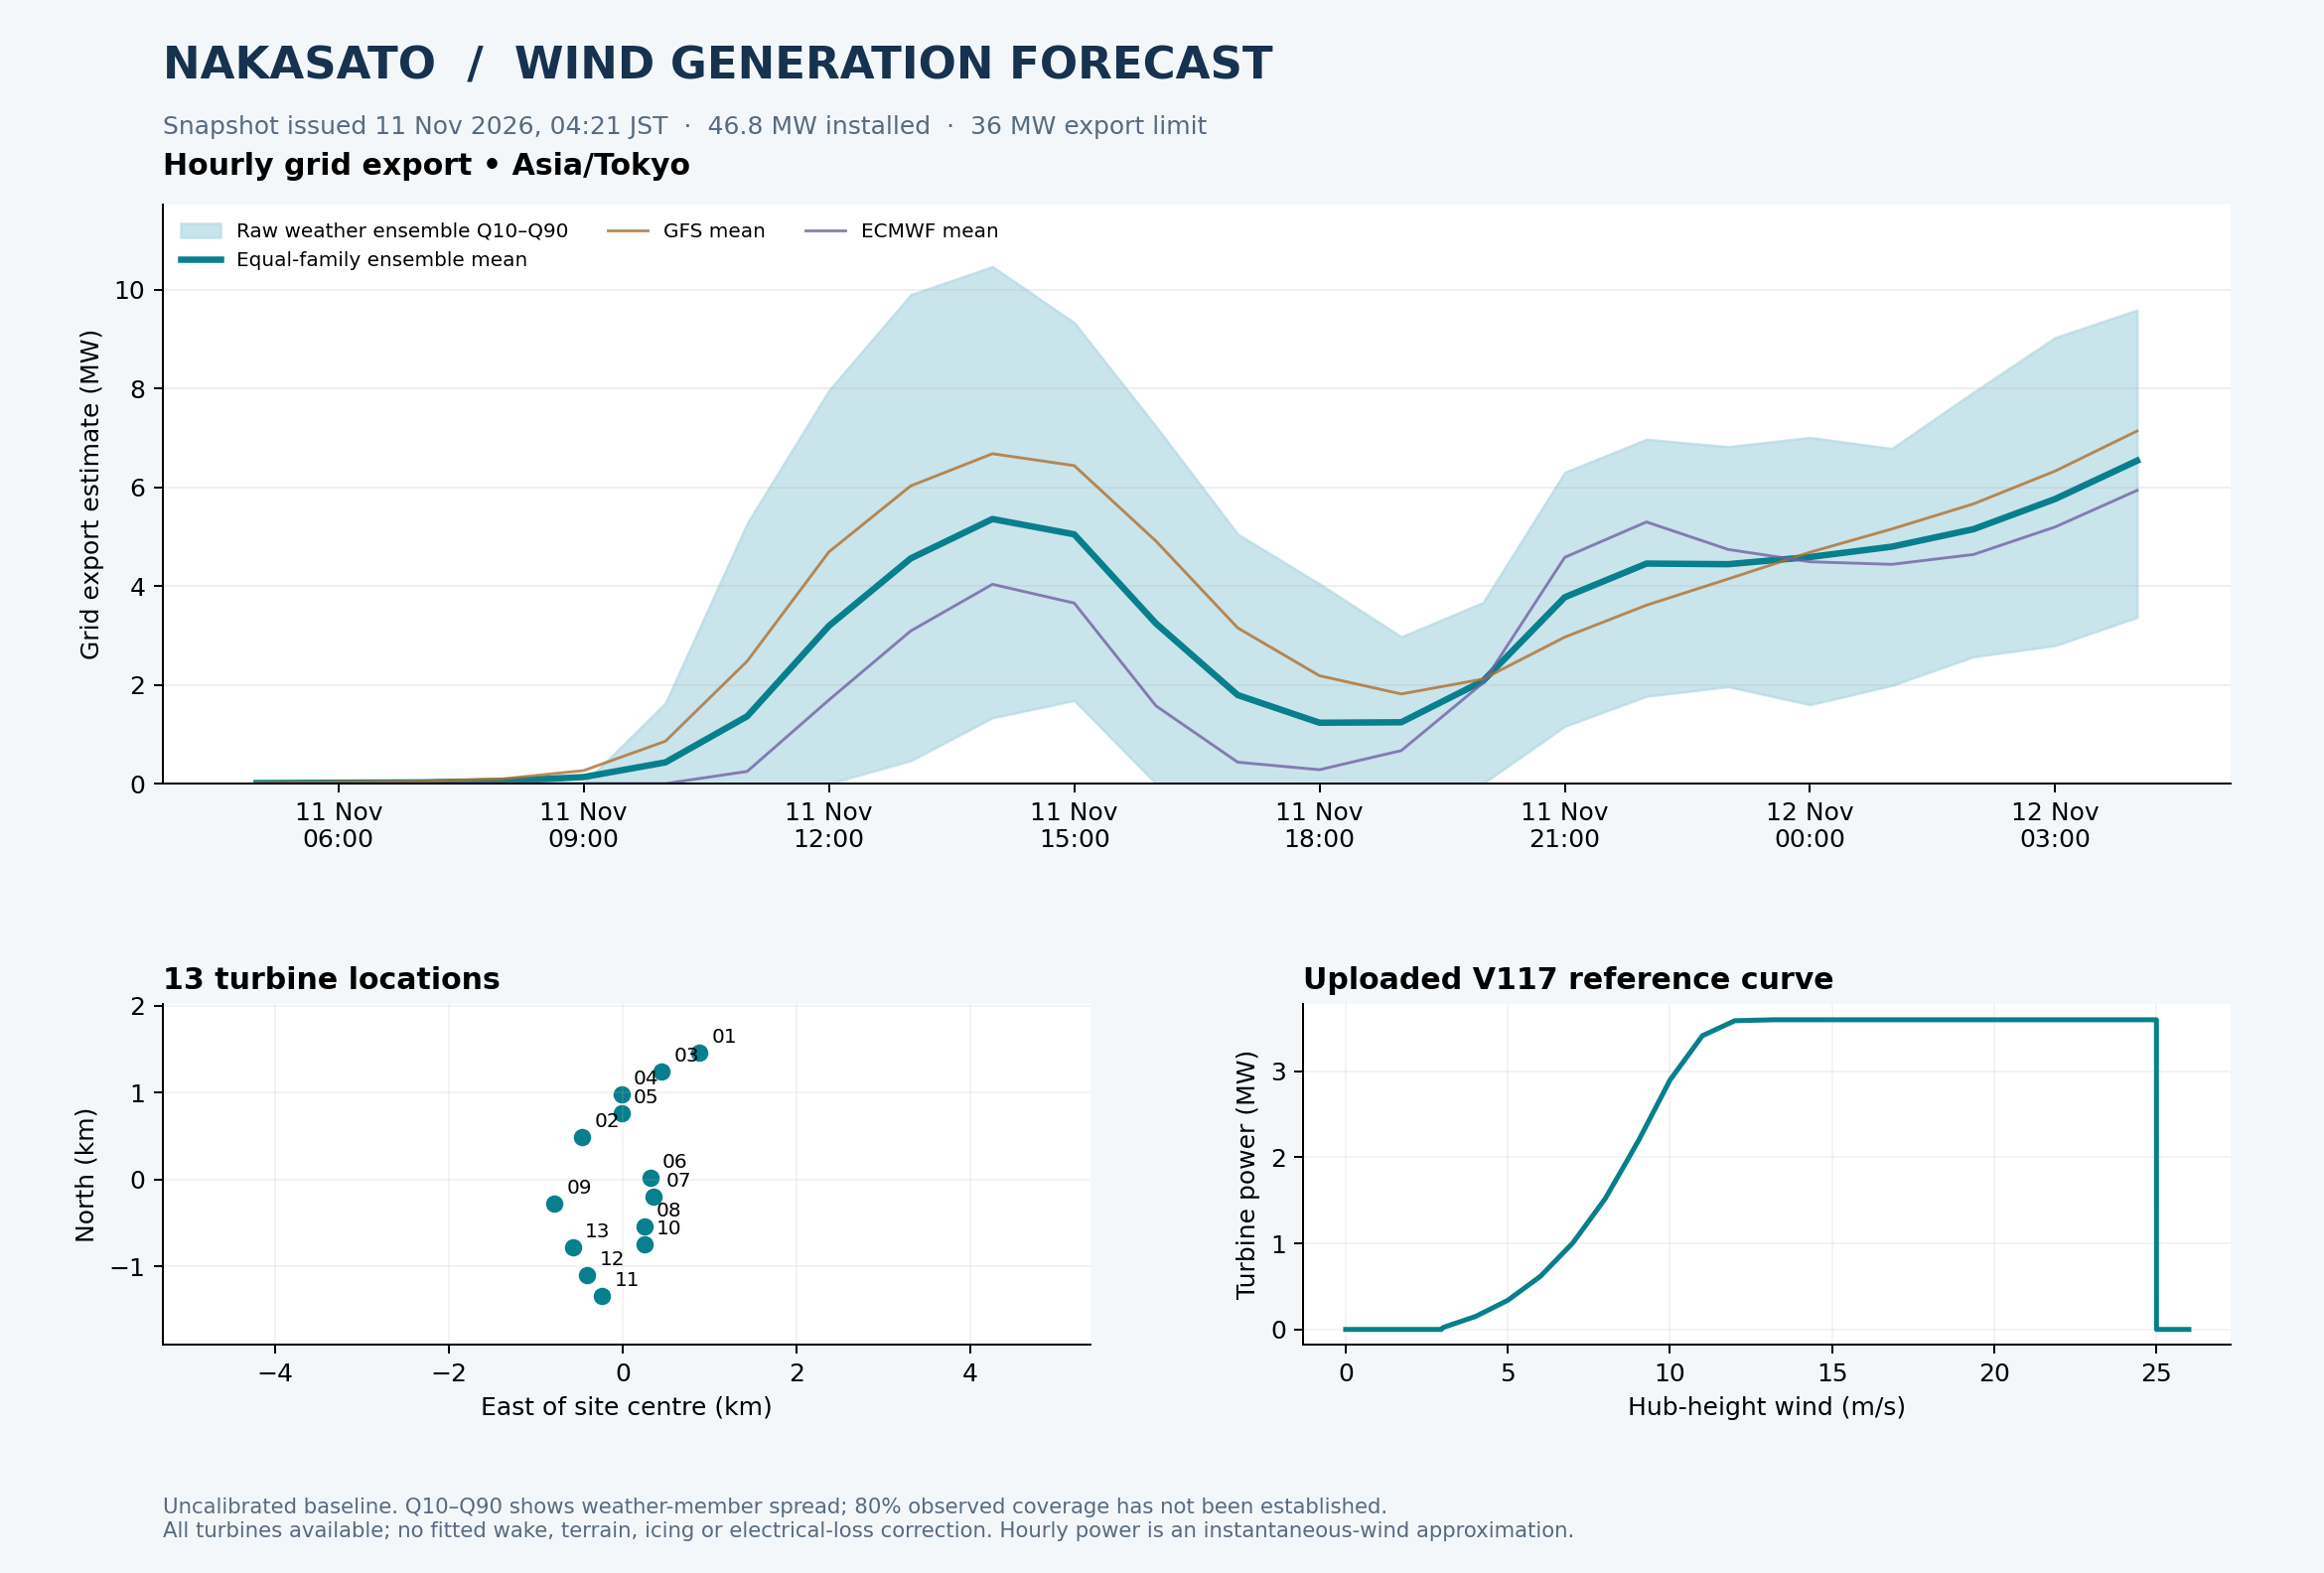

In [2]:
farm, turbine_forecasts, metadata = run_forecast(
    ROOT, ROOT/"examples/weather_snapshot", ROOT/"runs/notebook_replay"
)
display(farm[["valid_time_jst", "mean_power_kw", "q10_kw", "q50_kw", "q90_kw", "gross_mean_kw"]].head(12).round(1))
display(Image(filename=str(ROOT/"runs/notebook_replay/forecast_overview.png")))


## 2. What is being averaged?

For every turbine, time and weather member:

1. Adjust 100 m wind to 116.5 m: $v_h=v_{100}(116.5/100)^{0.14}$. The exponent is an initial assumption.
2. Convert that member's wind through the supplied power curve, with explicit cut-in/cut-out behavior.
3. Apply known turbine availability and power limits.
4. Sum turbines within the **same family and member**, apply electrical losses, and cap farm export at 36 MW.
5. Average power using weight $0.5/M_f$ per member in family $f$.

This computes $E[P(v)]$, rather than passing the average wind through a nonlinear curve.
The cap is also applied before averaging. Neighbouring turbines share much of their weather risk,
so farm quantiles must come from joint scenarios, not sums of turbine quantiles.

**Q10/Q50/Q90** are lower, median and upper CDF quantiles of raw weather-member power.
Q10–Q90 has **not** been shown to cover 80% of actual outcomes. These are not energy-finance
exceedance P-values. Hourly energy values assume each power sample represents one hour and are labelled proxies.


In [3]:
display(pd.DataFrame(metadata["audit"]).T)
display(pd.read_csv(ROOT/"runs/notebook_replay/weather_grid_audit.csv").head())
display(pd.read_csv(ROOT/"runs/notebook_replay/horizon_energy_proxy.csv").round(1))


,model,members_used,dropped_members,api_reference_height_m,distinct_returned_grids,distinct_site_wind_trajectories
gfs,gfs_seamless,31,[],100,1,1
ecmwf,ecmwf_ifs025,51,[],100,1,1
jma,jma_msm,1,[],10,1,1


,family,turbine_id,requested_latitude,requested_longitude,returned_latitude,returned_longitude,api_ground_elevation_m,reference_height_m
0,gfs,1,41.001908,140.468247,41.0,140.5,164.0,100
1,gfs,2,40.993257,140.452219,41.0,140.5,49.0,100
2,gfs,3,40.999956,140.463079,41.0,140.5,131.0,100
3,gfs,4,40.997579,140.457617,41.0,140.5,121.0,100
4,gfs,5,40.995715,140.457620,41.0,140.5,109.0,100


,issue_time_utc,mean_energy_proxy_kwh,q10_kwh,q50_kwh,q90_kwh,ensemble_std_kwh,n_scenarios,n_families,ecmwf_mean_kwh,gfs_mean_kwh,hours
0,2026-11-10T19:21:46.414871+00:00,69238.3,35827.5,66036.7,109495.5,27114.6,82,2,57013.7,81462.8,24


## 3. Site and power-curve assumptions

- The map has 13 turbines; the site owner reports 46.8 MW installed capacity and a **36 MW grid connection**.
- Hub height is configured at 116.5 m. Generic V117-3.45 MW specifications do not override your supplied **3.6 MW curve**.
- Both density tables in the workbook have identical power values. We select 1.225 kg/m³, sort by speed,
  and apply no additional density correction. Original units are inferred: confirm m/s, kW and kg/m³.
- The curve gives 3,600 kW at 25.0 m/s and zero at 25.1. No interpolation is allowed across this jump.
  The optional hourly restart approximation waits until <=23 m/s after a shutdown; initial state is assumed running.
- All turbines are available, local wind multipliers are 1, and electrical loss is 0 unless configured.
  Wakes, terrain, icing and unplanned outages have not been fitted.

The included API responses produce identical wind trajectories across the farm within each source.
Initial turbine forecasts can therefore match. Historical SCADA is needed to learn defensible local differences.


In [4]:
from wind_forecast.core import PowerCurve
curve = PowerCurve.read(ROOT/"data/power_curve.csv", cfg)
speeds = [2.9, 3.0, 5.0, 8.35, 13.0, 25.0, 25.01]
display(pd.DataFrame({"wind_speed_ms":speeds, "stateless_curve_power_kw":curve.evaluate(speeds)}))
display(pd.read_csv(ROOT/"runs/notebook_replay/jma_benchmark.csv").head(5))


,wind_speed_ms,stateless_curve_power_kw
0,2.90,0.0
1,3.00,22.0
2,5.00,339.0
3,8.35,1748.0
4,13.00,3600.0
5,25.00,3600.0
6,25.01,0.0


,issue_time_utc,valid_time_utc,family,member,gross_power_kw,available_power_kw,export_power_kw,label
0,2026-11-10T19:21:46.414871+00:00,2026-11-10T20:00:00+00:00,jma,0,0.0,0.0,0.0,JMA MSM 10 m + assumed power-law shear; benchm...
1,2026-11-10T19:21:46.414871+00:00,2026-11-10T21:00:00+00:00,jma,0,0.0,0.0,0.0,JMA MSM 10 m + assumed power-law shear; benchm...
2,2026-11-10T19:21:46.414871+00:00,2026-11-10T22:00:00+00:00,jma,0,0.0,0.0,0.0,JMA MSM 10 m + assumed power-law shear; benchm...
3,2026-11-10T19:21:46.414871+00:00,2026-11-10T23:00:00+00:00,jma,0,0.0,0.0,0.0,JMA MSM 10 m + assumed power-law shear; benchm...
4,2026-11-10T19:21:46.414871+00:00,2026-11-11T00:00:00+00:00,jma,0,0.0,0.0,0.0,JMA MSM 10 m + assumed power-law shear; benchm...


## 4. Fetch a fresh forecast (optional)

Set `RUN_LIVE = True` to call Open-Meteo. New raw inputs and outputs are archived by timestamp.
GFS/ECMWF are required; JMA is an optional benchmark, using 10 m winds with a larger height extrapolation.
The hourly export cap remains 36 MW. `hours` may be changed from 1 to 168; JMA's shorter horizon can omit later benchmark hours.


In [5]:
RUN_LIVE = False
if RUN_LIVE:
    from wind_forecast.weather import fetch_snapshot
    stamp = pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S%fZ")
    snapshot = fetch_snapshot(turbines, hours=24, destination=ROOT/"weather_archive"/stamp)
    live_farm, live_turbines, live_metadata = run_forecast(ROOT, snapshot, ROOT/"runs"/stamp)
    display(live_farm.head())
else:
    print("Live fetching disabled. Using the supplied dated snapshot.")


Live fetching disabled. Using the supplied dated snapshot.


## 5. Optional future calibration — not required to run this model

The implemented stack combines **physical mean + Random Forest + histogram gradient boosting + Ridge**.
The learned models correct the physical forecast's residuals. Nonnegative weights summing to one are fitted
using purged chronological out-of-fold predictions. The final 20% of issue times is held out. Labels must
have been available before each training cutoff; repeated forecast horizons are purged at split boundaries.

Prepare hourly SCADA with:

| Column | Meaning |
|---|---|
| `valid_time_utc` | Beginning of target hour, UTC |
| `turbine_id` | `01`–`13`, mapped to the source SCADA tags |
| `power_kw` | Actual mean active power for that hour |
| `observed_at_utc` | When that hourly label became available |

Retain each issued `forecast_features.csv`. Aim for 6–12 months of real labels **and archived forecast inputs**.
One forecast snapshot cannot train or validate a model. Historical reanalysis and target-time measured wind
must not be substituted for weather that was available at the forecast origin.

See `DATA_REQUIREMENTS.md` for subhourly aggregation, meter definitions and optional operation plans.
The following training cell is disabled until those files exist. It does not generate synthetic plant results.


In [6]:
TRAIN_WITH_REAL_DATA = False
if TRAIN_WITH_REAL_DATA:
    from wind_forecast.learning import train
    training_report = train(
        str(ROOT/"runs"/"**"/"forecast_features.csv"),
        ROOT/"data/scada.csv",
        ROOT/"models/calibrated"
    )
    display(pd.DataFrame(training_report["holdout_metrics"]).T)
else:
    print("ML training disabled: no historical SCADA labels were supplied with this project.")


ML training disabled: no historical SCADA labels were supplied with this project.


## 6. How to decide whether the ensemble is better

Compare persistence, each weather/physical family, the residual learners and their stack on the same
held-out periods. Use MAE, RMSE, capacity-normalized error and bias by lead time, turbine and season.
A future LSTM comparison should have the same inputs and temporal splits. An ensemble may win, but that
is a result to establish from site data, not an assumption.

Assess raw quantiles with pinball loss and observed coverage before treating them as calibrated intervals.
Use time blocks when assessing uncertainty in performance differences because turbines and overlapping
forecast targets are dependent. True farm-export validation also needs the export meter.

**Software validation:** 14 automated correctness tests passed, including a synthetic train/save/predict
test. Synthetic test scores are not evidence of plant performance. Run the tests with
`python -m unittest discover -s tests -v`.

## Sources and further reading

- [Open-Meteo Ensemble API](https://open-meteo.com/en/docs/ensemble-api)
- [Open-Meteo JMA API](https://open-meteo.com/en/docs/jma-api)
- [Single Runs API for historical forecast reconstruction](https://open-meteo.com/en/docs/single-runs-api)
- [Vena: Nakasato installed and grid capacity](https://venagroup.com/vena-energy-secures-jpy14-5b-shinsei-green-loan-for-the-construction-of-the-nakasato-wind-project-in-aomori-prefecture/)
- [Vena: 116.5 m hub height](https://project.venaenergy.co.jp/information/1078)
- [Vestas V117-3.45 MW reference specification](https://www.vestas.com/en/energy-solutions/onshore-wind-turbines/4-mw-platform/V117-3-45-MW)
- [Pinson & Madsen: ensemble forecasts converted to wind power](https://doi.org/10.1002/we.309)

The project also preserves the original uploaded workbook and retrieved site KML. See `MODEL_CARD.md`
for the full model definition and `TESTING.md` for validation scope.
